In [1]:
import pandas as pd
import numpy as np

In [2]:
import pandas as pd
import glob
import os
folder = "dataset/MachineLearningCVE"

files = glob.glob(folder + "/*.csv")

print("Total CSV files:", len(files))

for file in files:
    print(os.path.basename(file))


Total CSV files: 0


In [3]:
import os
import glob

folder = "dataset/MachineLearningCVE"

print("Folder exists:", os.path.exists(folder))

files = glob.glob(os.path.join(folder, "*.csv"))

print("CSV files found:", len(files))

for file in files:
    print(file)

Folder exists: False
CSV files found: 0


In [4]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFolders available:")
print(os.listdir())

Current working directory:
c:\Users\nagas\Desktop\network intrusion\notebooks

Folders available:
['01_dataset_exploration.ipynb']


In [5]:
import os
import glob

folder = "../dataset/MachineLearningCVE"

files = glob.glob(os.path.join(folder, "*.csv"))

print("Folder exists:", os.path.exists(folder))
print("CSV files found:", len(files))

for file in files:
    print(os.path.basename(file))

Folder exists: True
CSV files found: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [6]:
import pandas as pd

dataframes = []

for file in files:
    df = pd.read_csv(file)
    df.columns = df.columns.str.strip()
    df["Source_File"] = os.path.basename(file)
    dataframes.append(df)

combined_df = pd.concat(dataframes, ignore_index=True)

print("Combined dataset shape:", combined_df.shape)

display(combined_df.head())

Combined dataset shape: (2830743, 80)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Source_File
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [7]:
print(combined_df["Label"].value_counts())

Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [8]:
print("Total missing values:",
      combined_df.isnull().sum().sum())

print("Total duplicate rows:",
      combined_df.duplicated().sum())

Total missing values: 1358
Total duplicate rows: 256479


In [9]:
import numpy as np

numeric_df = combined_df.select_dtypes(include=["number"])

infinite_count = np.isinf(numeric_df).sum().sum()

print("Total infinite values:", infinite_count)

Total infinite values: 4376


In [ ]:
combined_df.to_csv(
    "../dataset/combined_traffic.csv",
    index=False
)

print("Dataset saved successfully!")

In [ ]:
cleaned_df = combined_df.copy()

print("Original shape:", cleaned_df.shape)

Original shape: (2830743, 80)


In [ ]:
before = len(cleaned_df)

cleaned_df = cleaned_df.drop_duplicates(
    subset=[col for col in cleaned_df.columns if col != "Source_File"]
)

after = len(cleaned_df)

print("Duplicates removed:", before - after)
print("Shape after removing duplicates:", cleaned_df.shape)

Duplicates removed: 308381
Shape after removing duplicates: (2522362, 80)


In [ ]:
import numpy as np

cleaned_df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Infinite values remaining:",
      np.isinf(cleaned_df.select_dtypes(include="number")).sum().sum())

Infinite values remaining: 0


In [ ]:
missing = cleaned_df.isnull().sum()

print(missing[missing > 0].sort_values(ascending=False))

Flow Bytes/s      1564
Flow Packets/s    1564
dtype: int64


In [ ]:
cleaned_df = cleaned_df.dropna(subset=["Label"])

print("Shape after removing missing labels:", cleaned_df.shape)

Shape after removing missing labels: (2522362, 80)


In [ ]:
cleaned_df["Label"] = (
    cleaned_df["Label"].astype(str).str.strip()
)

cleaned_df["Binary_Label"] = (
    cleaned_df["Label"] != "BENIGN"
).astype(int)

In [ ]:
print(cleaned_df["Binary_Label"].value_counts())

print("\nOriginal attack categories:")
print(cleaned_df["Label"].value_counts())

Binary_Label
0    2096484
1     425878
Name: count, dtype: int64

Original attack categories:
Label
BENIGN                        2096484
DoS Hulk                       172849
DDoS                           128016
PortScan                        90819
DoS GoldenEye                   10286
FTP-Patator                      5933
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1953
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [ ]:
cleaned_df.to_csv(
    "../dataset/cleaned_traffic.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
print("Total columns:", len(cleaned_df.columns))

for col in cleaned_df.columns:
    print(col)

Total columns: 81
Destination Port
Flow Duration
Total Fwd Packets
Total Backward Packets
Total Length of Fwd Packets
Total Length of Bwd Packets
Fwd Packet Length Max
Fwd Packet Length Min
Fwd Packet Length Mean
Fwd Packet Length Std
Bwd Packet Length Max
Bwd Packet Length Min
Bwd Packet Length Mean
Bwd Packet Length Std
Flow Bytes/s
Flow Packets/s
Flow IAT Mean
Flow IAT Std
Flow IAT Max
Flow IAT Min
Fwd IAT Total
Fwd IAT Mean
Fwd IAT Std
Fwd IAT Max
Fwd IAT Min
Bwd IAT Total
Bwd IAT Mean
Bwd IAT Std
Bwd IAT Max
Bwd IAT Min
Fwd PSH Flags
Bwd PSH Flags
Fwd URG Flags
Bwd URG Flags
Fwd Header Length
Bwd Header Length
Fwd Packets/s
Bwd Packets/s
Min Packet Length
Max Packet Length
Packet Length Mean
Packet Length Std
Packet Length Variance
FIN Flag Count
SYN Flag Count
RST Flag Count
PSH Flag Count
ACK Flag Count
URG Flag Count
CWE Flag Count
ECE Flag Count
Down/Up Ratio
Average Packet Size
Avg Fwd Segment Size
Avg Bwd Segment Size
Fwd Header Length.1
Fwd Avg Bytes/Bulk
Fwd Avg Packets/Bu

In [ ]:
drop_columns = [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp",
    "Source_File",
    "Label"
]

X = cleaned_df.drop(
    columns=drop_columns + ["Binary_Label"],
    errors="ignore"
)

y = cleaned_df["Binary_Label"]

In [ ]:
X = X.select_dtypes(include=["number"])

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

Feature shape: (2522362, 78)
Target shape: (2522362,)

Selected features:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Cou

In [ ]:
print("Missing values in X:", X.isnull().sum().sum())

print("Infinite values in X:",
      np.isinf(X).sum().sum())

print("\nTarget distribution:")
print(y.value_counts())

Missing values in X: 3128
Infinite values in X: 0

Target distribution:
Binary_Label
0    2096484
1     425878
Name: count, dtype: int64


In [ ]:
X.to_csv("../dataset/features.csv", index=False)

y.to_csv("../dataset/target.csv", index=False)

print("Features and target saved successfully!")

Features and target saved successfully!


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (2017889, 78)
Testing features: (504473, 78)
Training labels: (2017889,)
Testing labels: (504473,)


In [ ]:
print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training class distribution:
Binary_Label
0    1677187
1     340702
Name: count, dtype: int64

Testing class distribution:
Binary_Label
0    419297
1     85176
Name: count, dtype: int64


In [ ]:
print("Training percentage:",
      len(X_train) / len(X) * 100)

print("Testing percentage:",
      len(X_test) / len(X) * 100)

Training percentage: 79.999976212772
Testing percentage: 20.000023787228002


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [ ]:
lr_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    )
)

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [ ]:
rf_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
dt_model = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(
        max_depth=15,
        class_weight="balanced",
        random_state=42
    )
)

dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [ ]:
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

print("All three models are ready!")

All three models are ready!


In [ ]:
for name, model in models.items():
    
    predictions = model.predict(X_test)

    print("\nModel:", name)
    print("First 10 predictions:", predictions[:10])


Model: Logistic Regression
First 10 predictions: [0 0 0 1 0 1 0 0 0 0]

Model: Decision Tree
First 10 predictions: [0 0 0 1 0 1 0 0 0 0]

Model: Random Forest
First 10 predictions: [0 0 0 1 0 1 0 0 0 0]


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [ ]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.9397     0.7454  0.9768    0.8455
1        Decision Tree    0.9987     0.9933  0.9993    0.9963
2        Random Forest    0.9988     0.9956  0.9975    0.9965


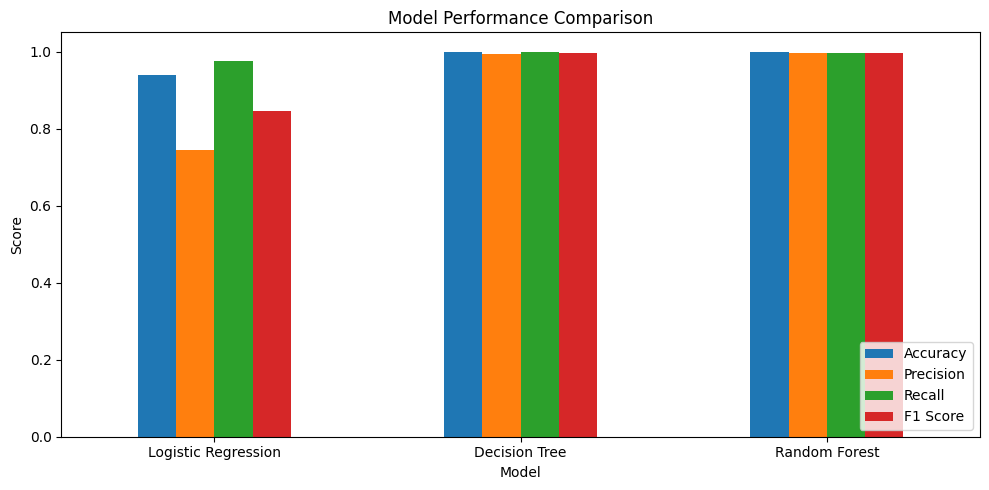

In [ ]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

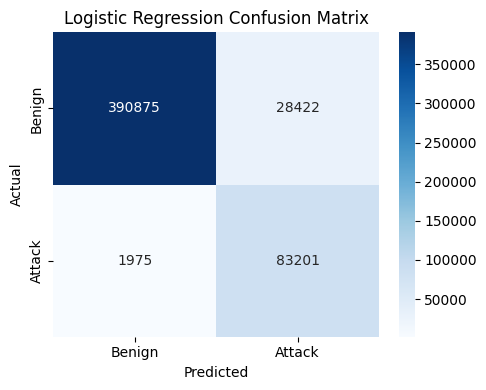

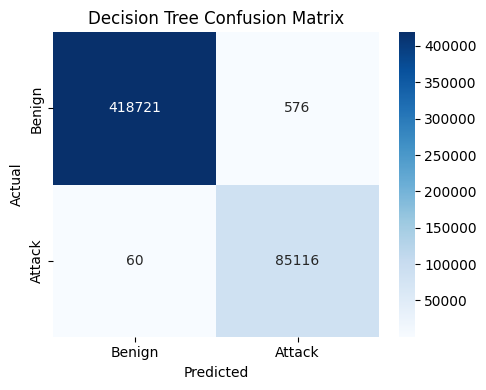

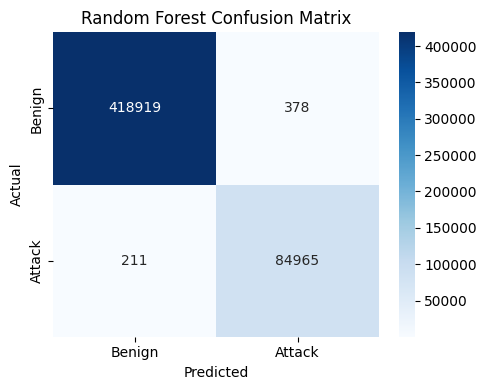

In [ ]:
for name, model in models.items():
    
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Benign", "Attack"],
        yticklabels=["Benign", "Attack"]
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

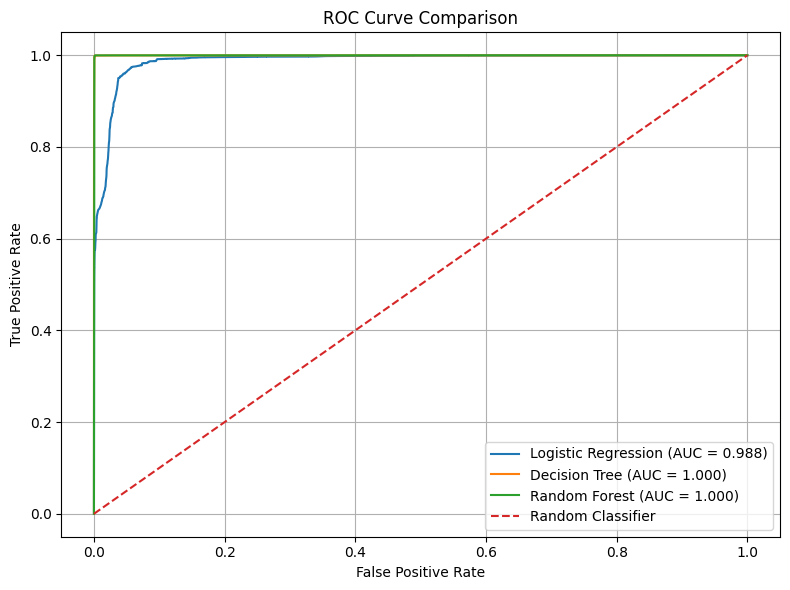

In [ ]:
plt.figure(figsize=(8, 6))

for name, model in models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]

In [ ]:
for name, model in models.items():
    
    y_pred = model.predict(X_test)

    print("\n==========", name, "==========")

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Benign", "Attack"],
        zero_division=0
    ))


========== Logistic Regression ==========
              precision    recall  f1-score   support

      Benign       0.99      0.93      0.96    419297
      Attack       0.75      0.98      0.85     85176

    accuracy                           0.94    504473
   macro avg       0.87      0.95      0.90    504473
weighted avg       0.95      0.94      0.94    504473


========== Decision Tree ==========
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    419297
      Attack       0.99      1.00      1.00     85176

    accuracy                           1.00    504473
   macro avg       1.00      1.00      1.00    504473
weighted avg       1.00      1.00      1.00    504473


========== Random Forest ==========
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    419297
      Attack       1.00      1.00      1.00     85176

    accuracy                           1.00    504473
   macro av

In [ ]:
import os

os.makedirs("../reports", exist_ok=True)

print("Reports folder created successfully!")

Reports folder created successfully!


In [ ]:
plt.savefig(
    "../reports/roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
print(os.listdir("../reports"))

['roc_curve.png']


In [ ]:
best_result = results_df.sort_values(
    by=["Recall", "F1 Score"],
    ascending=False
).iloc[0]

best_model_name = best_result["Model"]

print("Selected model:", best_model_name)

best_model = models[best_model_name]

Selected model: Decision Tree


In [ ]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/best_model.pkl"
)

joblib.dump(
    list(X_train.columns),
    "../models/features.pkl"
)

print("Model and features saved successfully!")

Model and features saved successfully!


In [ ]:
pip install streamlit joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\nagas\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import os

print("Models folder exists:", os.path.exists("../models"))

print("Files inside models folder:")

if os.path.exists("../models"):
    print(os.listdir("../models"))

Models folder exists: True
Files inside models folder:
['best_model.pkl', 'features.pkl']


In [ ]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(best_model, "../models/best_model.pkl")

joblib.dump(list(X_train.columns), "../models/features.pkl")

print(os.listdir("../models"))

['best_model.pkl', 'features.pkl']


: 